# Audit and Exploration: AI Exposure Predicts Unemployment Risk

This notebook audits and explores the dataset from Frank et al. (2025), "AI exposure predicts unemployment risk".

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment initialized. Ready to load dataset.")

Environment initialized. Ready to load dataset.


## Step 1: Loading Datasets and Inspecting the Columns


In [2]:
# URLs for the datasets
unemployment_risk_url = "https://raw.githubusercontent.com/mrfrank8176/unemploymentRisk/main/demoData_unemploymentRisk.csv"
automation_by_state_url = "https://raw.githubusercontent.com/mrfrank8176/unemploymentRisk/main/demoData_automationByState.csv"

# Load datasets
df_risk = pd.read_csv(unemployment_risk_url)
df_auto = pd.read_csv(automation_by_state_url)

# Display columns and shapes
print("--- Unemployment Risk Dataset Info ---")
print(f"Shape: {df_risk.shape}")
print(f"Columns: {list(df_risk.columns)}")
display(df_risk.head())

print("\n--- Automation By State Dataset Info ---")
print(f"Shape: {df_auto.shape}")
print(f"Columns: {list(df_auto.columns)}")
display(df_auto.head())

--- Unemployment Risk Dataset Info ---
Shape: (140274, 9)
Columns: ['Unnamed: 0', 'state', 'st', 'year', 'month', '2SOC', 'Unemployment Risk', 'Total Unemployment Rate (%)', 'Unemployment Count']


,Unnamed: 0,state,st,year,month,2SOC,Unemployment Risk,Total Unemployment Rate (%),Unemployment Count
0,0,Alabama,AL,2010,1,11,0.003038,11.448858,4178
1,1,Alabama,AL,2010,2,11,0.002917,11.085179,4077
2,2,Alabama,AL,2010,3,11,0.002931,10.754540,3916
3,3,Alabama,AL,2010,4,11,0.002691,9.846164,3705
4,4,Alabama,AL,2010,5,11,0.002698,9.651209,3521



--- Automation By State Dataset Info ---
Shape: (549, 16)
Columns: ['Unnamed: 0', 'year', 'state', 'month', 'Acemoglu & Autor Comp.Use', 'Acemoglu & Autor R.Cog.', 'Acemoglu & Autor R.Man.', 'ONET Education %college', 'Frey & Osborne auto', 'Arntz et al auto', 'ONET Automation Deg.Auto.', 'Brynjolfsson et al SML', 'Felten et al AI', 'Webb AI', 'Webb Robot', 'Webb Software']


,Unnamed: 0,year,state,month,Acemoglu & Autor Comp.Use,Acemoglu & Autor R.Cog.,Acemoglu & Autor R.Man.,ONET Education %college,Frey & Osborne auto,Arntz et al auto,ONET Automation Deg.Auto.,Brynjolfsson et al SML,Felten et al AI,Webb AI,Webb Robot,Webb Software
0,0,2010,AK,1,0.650780,-0.385926,-0.623702,0.366802,0.174588,0.142123,0.218134,0.563278,3.558259,65.016967,23.694087,46.263239
1,1,2010,AL,1,0.634850,-0.370374,-0.586113,0.336282,0.123737,0.139628,0.218478,0.562817,3.544763,65.972539,23.217806,45.789565
2,2,2010,AR,1,0.625480,-0.346294,-0.630219,0.334520,0.160773,0.159131,0.217509,0.558524,3.535279,64.181343,22.657812,44.472914
3,3,2010,AZ,1,0.655891,-0.337029,-0.635396,0.352782,0.152755,0.161317,0.220636,0.567099,3.565156,66.706672,24.056527,46.714463
4,4,2010,CA,1,0.965681,0.355029,-0.438817,0.006700,0.075879,0.092822,0.159536,0.435019,2.682811,60.639335,27.268805,52.160351


In [4]:
# 1. Check if 'Unnamed: 0' is just a copy of the index, and drop it if True
risk_unnamed_is_index = (df_risk['Unnamed: 0'] == df_risk.index).all()
auto_unnamed_is_index = (df_auto['Unnamed: 0'] == df_auto.index).all()

print(f"Is 'Unnamed: 0' in df_risk a copy of the index? {risk_unnamed_is_index}")
print(f"Is 'Unnamed: 0' in df_auto a copy of the index? {auto_unnamed_is_index}")

if risk_unnamed_is_index:
    df_risk = df_risk.drop(columns=['Unnamed: 0'])

if auto_unnamed_is_index:
    df_auto = df_auto.drop(columns=['Unnamed: 0'])

# 2. Rename columns in df_risk to shorter, cleaner names
rename_dict = {
    '2SOC': 'soc',
    'Unemployment Risk': 'risk',
    'Total Unemployment Rate (%)': 'state_rate',
    'Unemployment Count': 'claimants'
}
df_risk = df_risk.rename(columns=rename_dict)

# 3. Print the data types of df_risk
print("\n--- df_risk Column Data Types ---")
print(df_risk.dtypes)

# 4. Print dataset statistics
print("\n--- df_risk Summary Statistics ---")
print(f"Total number of rows: {len(df_risk)}")
print(f"Number of unique states (st): {df_risk['st'].nunique()}")
print(f"Year range: {df_risk['year'].min()} to {df_risk['year'].max()}")
print(f"Number of unique SOC codes: {df_risk['soc'].nunique()}")

# 5. Check for duplicate rows on the combination of st, year, month, and soc
duplicate_keys = ['st', 'year', 'month', 'soc']
num_duplicates = df_risk.duplicated(subset=duplicate_keys).sum()
print(f"\nNumber of duplicate rows on {duplicate_keys}: {num_duplicates}")

# 6. Count rows by year splits (<= 2019 vs 2020)
rows_pre_2020 = (df_risk['year'] <= 2019).sum()
rows_2020 = (df_risk['year'] == 2020).sum()
print(f"\nNumber of rows with year <= 2019: {rows_pre_2020}")
print(f"Number of rows with year == 2020: {rows_2020}")

Is 'Unnamed: 0' in df_risk a copy of the index? True
Is 'Unnamed: 0' in df_auto a copy of the index? True

--- df_risk Column Data Types ---
state          object
st             object
year            int64
month           int64
soc             int64
risk          float64
state_rate    float64
claimants       int64
dtype: object

--- df_risk Summary Statistics ---
Total number of rows: 140274
Number of unique states (st): 50
Year range: 2010 to 2020
Number of unique SOC codes: 22

Number of duplicate rows on ['st', 'year', 'month', 'soc']: 0

Number of rows with year <= 2019: 127452
Number of rows with year == 2020: 12822


In [5]:
# 1. Print the number of NaN values in each column
print("--- Missing (NaN) Values per Column ---")
print(df_risk.isna().sum())

# 2. Print claimants == 0 count and minimum value of claimants
zero_claimants_count = (df_risk['claimants'] == 0).sum()
min_claimants = df_risk['claimants'].min()
print(f"\nNumber of rows with claimants == 0: {zero_claimants_count}")
print(f"Minimum value of claimants: {min_claimants}")

# 3. Calculate panel completeness (50 states x 11 years x 12 months x 22 SOC codes)
expected_count = 50 * 11 * 12 * 22
actual_count = len(df_risk)
missing_rows = expected_count - actual_count
pct_missing = (missing_rows / expected_count) * 100

print("\n--- Panel Completeness Audit ---")
print(f"Expected rows in complete panel: {expected_count}")
print(f"Actual rows in df_risk: {actual_count}")
print(f"Missing rows: {missing_rows}")
print(f"Percentage missing: {pct_missing:.2f}%")

# 4. Print the 8 states with the fewest rows
print("\n--- 8 States with the Fewest Rows ---")
print(df_risk['st'].value_counts().tail(8))

# 5. California (CA) crosstab of 'soc' against 'year'
print("\n--- California (CA) SOC vs Year Crosstab ---")
df_ca = df_risk[df_risk['st'] == 'CA']
ca_crosstab = pd.crosstab(df_ca['soc'], df_ca['year'])
display(ca_crosstab)

# 6. Print number of rows per year for Connecticut (CT)
print("\n--- Connecticut (CT) Rows per Year ---")
df_ct = df_risk[df_risk['st'] == 'CT']
print(df_ct['year'].value_counts().sort_index())

--- Missing (NaN) Values per Column ---
state         0
st            0
year          0
month         0
soc           0
risk          0
state_rate    0
claimants     0
dtype: int64

Number of rows with claimants == 0: 0
Minimum value of claimants: 1

--- Panel Completeness Audit ---
Expected rows in complete panel: 145200
Actual rows in df_risk: 140274
Missing rows: 4926
Percentage missing: 3.39%

--- 8 States with the Fewest Rows ---
st
AK    2865
KY    2828
SC    2818
PA    2817
KS    2772
RI    2595
CT    1004
CA     660
Name: count, dtype: int64

--- California (CA) SOC vs Year Crosstab ---


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
soc,,,,,,,,,,,
15,12,12,12,12,12,12,12,12,12,12,12
35,12,12,12,12,12,12,12,12,12,12,12
41,12,12,12,12,12,12,12,12,12,12,12
45,12,12,12,12,12,12,12,12,12,12,12
49,1,0,0,0,0,0,0,0,0,0,0
51,11,12,12,12,12,12,12,12,12,12,12



--- Connecticut (CT) Rows per Year ---
year
2010    144
2011    112
2012     96
2013     97
2014     90
2015    102
2016     91
2017     58
2018     53
2019     48
2020    113
Name: count, dtype: int64


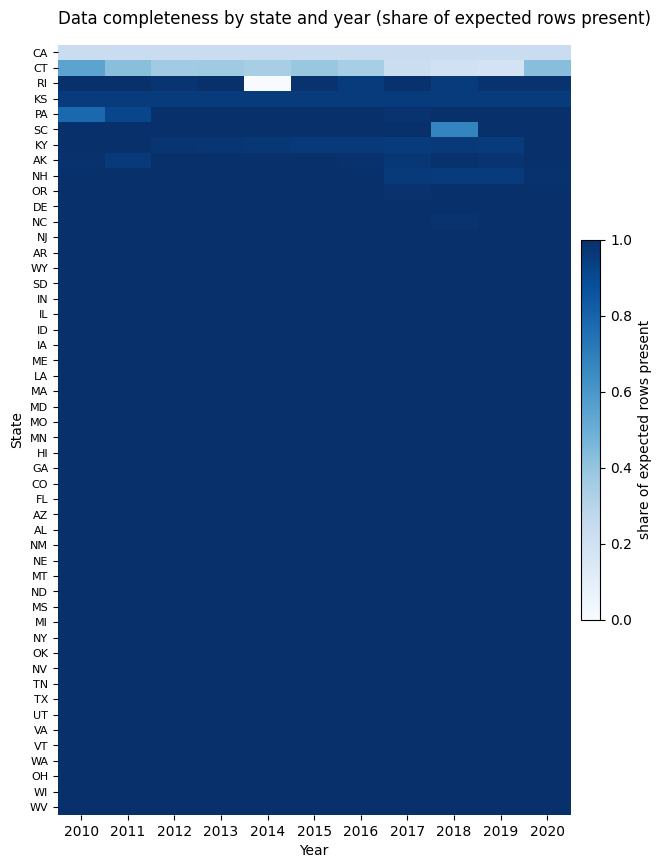

In [7]:
# 1. Group by state and year, count rows, and calculate the completeness fraction
completeness = df_risk.groupby(['st', 'year']).size().reset_index(name='count')
completeness['share'] = completeness['count'] / 264.0

# 2. Pivot the data to create a matrix with states on rows and years on columns
matrix = completeness.pivot(index='st', columns='year', values='share').fillna(0.0)

# 3. Sort states by average completeness so the least complete are at the top
matrix = matrix.loc[matrix.mean(axis=1).sort_values().index]

# 4. Plot the heatmap using plt.imshow with updated figsize
fig, ax = plt.subplots(figsize=(7, 10))
im = ax.imshow(matrix.values, cmap='Blues', aspect='auto', vmin=0.0, vmax=1.0)

# 5. Add colorbar with updated size parameters
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label('share of expected rows present')

# Set years on the x-axis
ax.set_xticks(range(len(matrix.columns)))
ax.set_xticklabels(matrix.columns)
ax.set_xlabel('Year')

# Set state codes on the y-axis with a small font
ax.set_yticks(range(len(matrix.index)))
ax.set_yticklabels(matrix.index, fontsize=8)
ax.set_ylabel('State')

# Hide axis spines (the black border around the heatmap)
for spine in ax.spines.values():
    spine.set_visible(False)

# Left-align the new title
ax.set_title('Data completeness by state and year (share of expected rows present)', loc='left', pad=15)

# 6. Save the figure as a PNG file with tight margins and specified DPI before showing
plt.savefig('fig1_completeness.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# 1. Print summary statistics for the risk column
print("--- df_risk['risk'] Summary Statistics ---")
print(df_risk['risk'].describe())

# 2. Find and count rows where risk > 1
outliers = df_risk[df_risk['risk'] > 1]
print(f"\nNumber of rows where risk > 1: {len(outliers)}")

if len(outliers) > 0:
    print("\n--- Counts of risk > 1 by state (st) and occupation (soc) ---")
    print(outliers.groupby(['st', 'soc']).size())

# 3. Rearrange the formula to compute implied employment and add as a new column
# risk = claimants / (claimants + employed) => implied_employed = (claimants / risk) - claimants
df_risk['implied_employed'] = (df_risk['claimants'] / df_risk['risk']) - df_risk['claimants']

# 4. Display Alabama (AL) rows for Jan 2015 formatted for easy reading
print("\n--- Alabama (AL) Jan 2015 Employment Metrics ---")
al_subset = df_risk[(df_risk['st'] == 'AL') & (df_risk['year'] == 2015) & (df_risk['month'] == 1)]
al_subset_sorted = al_subset[['soc', 'claimants', 'risk', 'implied_employed']].sort_values(by='implied_employed', ascending=False)

# Display table with styled formatting and hidden index
display(al_subset_sorted.style.format({
    'claimants': '{:,.0f}',
    'risk': '{:.5f}',
    'implied_employed': '{:,.0f}'
}).hide())

# 5. Sum implied_employed and compare with BLS labor force
total_implied = al_subset_sorted['implied_employed'].sum()
bls_labor_force = 2172619
times_larger = total_implied / bls_labor_force

print(f"\nTotal implied employed across all occupations: {total_implied:,.0f}")
print(f"This is {times_larger:.1f} times larger than Alabama's actual 2015 BLS labour force of 2,172,619.")

--- df_risk['risk'] Summary Statistics ---
count    1.402740e+05
mean     2.617547e-03
std      2.596278e-02
min      1.409497e-07
25%      3.881777e-04
50%      7.501609e-04
75%      1.417753e-03
max      2.416900e+00
Name: risk, dtype: float64

Number of rows where risk > 1: 26

--- Counts of risk > 1 by state (st) and occupation (soc) ---
st  soc
AK  45      9
RI  45     17
dtype: int64

--- Alabama (AL) Jan 2015 Employment Metrics ---


soc,claimants,risk,implied_employed
51,"3,904",0.00045,"8,706,587"
43,"3,566",0.00055,"6,426,993"
29,592,0.00020,"2,897,797"
25,353,0.00013,"2,666,507"
53,"1,796",0.00070,"2,556,259"
49,"1,112",0.00059,"1,888,948"
41,"1,839",0.00103,"1,777,301"
47,"2,731",0.00173,"1,577,048"
35,"1,286",0.00109,"1,182,800"
11,"1,866",0.00196,"947,979"



Total implied employed across all occupations: 34,321,724
This is 15.8 times larger than Alabama's actual 2015 BLS labour force of 2,172,619.
